In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scipy.optimize import brentq
from scipy.interpolate import interp1d
import seaborn as sns

In [2]:
def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)

    print(f"AUC: {rocauc * 100:.2f}%, EER: {eer * 100:.2f}%")

def show_expert_contributions(contrib, contrib_norm, labels_names):
    n_exp = len(contrib)

    print("\n=== Ranked Experts ===\n")

    for i, c in sorted(enumerate(contrib), key=lambda x: -x[1]):
        name = labels_names[i]
        print(f"{i:>2} | {name:<12} | contribution: {c:>8.4f} | normalized: {contrib_norm[i]:>7.4f}")

    print("\nSummary:")
    print(f"Positive contributors: {np.sum(contrib > 0)} {np.where(contrib > 0)[0].tolist()}")
    print(f"Negative contributors: {np.sum(contrib < 0)} {np.where(contrib < 0)[0].tolist()}")

    plt.figure()
    plt.bar(range(n_exp), contrib_norm)
    plt.axhline(0, color='black')

    plt.xticks(range(n_exp), labels_names, rotation=30, ha="right")
    plt.ylabel("Normalized Contribution")

    plt.tight_layout()
    plt.show()
    
def analyze_ensemble(rootpath, expert_names=None):
    labels = np.load(os.path.join(rootpath, "labels.npy"))

    # PRINT PERFORMANCE METRICS  

    ensemble_logLR = np.load(os.path.join(rootpath, "scores.npy"))
    print(f"Loaded {len(ensemble_logLR)} samples")

    print("\n#--------- OVERALL ENSEMBLE ---------#\n")
    print_metrics(ensemble_logLR, labels)

    real = ensemble_logLR[labels == 0]
    fake = ensemble_logLR[labels == 1]

    print(f"Real mean score: {real.mean():.4f}")
    print(f"Fake mean score: {fake.mean():.4f}\n")

    print("\n#------------ PER EXPERT ------------#\n")

    all_logLR = np.load(os.path.join(rootpath, "scores_per_expert.npy"))
    n_exp = all_logLR.shape[0]

    real_all_logLR = []
    fake_all_logLR = []

    for i in range(n_exp):
        name = expert_names[i] if expert_names else f"Expert {i}"

        print(f"--- {name} ---")
        per_expert_logLR = all_logLR[i]

        print_metrics(per_expert_logLR, labels)

        real_i = per_expert_logLR[labels == 0]
        fake_i = per_expert_logLR[labels == 1]

        print(f"Real mean score: {real_i.mean():.4f}")
        print(f"Fake mean score: {fake_i.mean():.4f}\n")

        real_all_logLR.append(real_i)
        fake_all_logLR.append(fake_i)

    # HIGHLIGHT EXPERT CONTRIBUTIONS    

    n_exp = all_logLR.shape[0]   # no. of experts
    N = all_logLR.shape[1]       # no. of test samples
    
    contrib = np.zeros(n_exp)
    
    for i in range(N):
        y_sign = 1 if labels[i] == 1 else -1
    
        for e in range(n_exp):
            contrib[e] += all_logLR[e, i] * y_sign
    
    contrib /= N
    contrib_norm = contrib / np.max(np.abs(contrib))
    
    show_expert_contributions(contrib, contrib_norm, names)
    
    return {
        "ensemble": ensemble_logLR,
        "per_expert": all_logLR,
        "labels": labels,
        "real": real_all_logLR,
        "fake": fake_all_logLR
    }

def plot_platt(a, b, logits, ax=None, title=""):
    if ax is None:
        ax = plt.gca()
    z_full = np.linspace(-10, 10, 1000)
    p_full = 1 / (1 + np.exp(-(a * z_full + b)))
    
    z_min, z_max = logits.min(), logits.max()
    z_data = np.linspace(z_min, z_max, 500)
    
    p_data = 1 / (1 + np.exp(-(a * z_data + b)))
    p_min = 1 / (1 + np.exp(-(a * z_min + b)))
    p_max = 1 / (1 + np.exp(-(a * z_max + b)))
    
    ax.plot(z_full, p_full, label="Full sigmoid", alpha=0.5)
    ax.plot(z_data, p_data, linewidth=3, label="Used region")
    
    ax.scatter([z_min, z_max], [p_min, p_max], color="red", zorder=3, label="min/max raw logits")
    ax.axvline(z_min, linestyle="--", alpha=0.5)
    ax.axvline(z_max, linestyle="--", alpha=0.5)

    lbound = np.percentile(logits, 5)
    hbound = np.percentile(logits, 95)
    ax.axvspan(lbound, hbound, color="yellow", alpha=0.3)
    ax.axvline(lbound, color="grey")
    ax.axvline(hbound, color="grey")
    
    ax.set_xlabel("logits (z)")
    ax.set_ylabel("probability")
    ax.set_title(title)
    #ax.legend()
    ax.grid()

def plot_platt_all_attacks(root_base, attacks, expert_names):
    n_exp = len(expert_names)
    n_att = len(attacks)

    fig, axes = plt.subplots(n_exp, n_att, figsize=(4*n_att, 3*n_exp), squeeze=False)

    for j, att in enumerate(attacks):
        path = os.path.join(root_base, att)

        logits_all = np.load(os.path.join(path, 'raw_logits_per_expert.npy'))
        a_all = np.load(os.path.join(root_base, 'all_a.npy'))
        b_all = np.load(os.path.join(root_base, 'all_b.npy'))

        for i in range(n_exp):
            ax = axes[i, j]

            logits = logits_all[i]
            a = a_all[i]
            b = b_all[i]

            plot_platt(a, b, logits, ax=ax)

            # --- labels ---
            if i == 0:
                ax.set_title(att)  # colonna = attacco
            if j == 0:
                ax.set_ylabel(expert_names[i])  # riga = expert

    plt.tight_layout()
    plt.show()

In [3]:
names = ['Flat Pitch', 'F0 Incons', 'Oversmooth', 'Phase', 'Energy']

# Test set: ASVspoof 2019


In [4]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']

## BEST MODEL @ Fri 27 March
### NEW oversm. and energy expert

Loaded 19171 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 90.91%, EER: 17.21%
Real mean score: -1.3294
Fake mean score: 2.8500


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 42.33%, EER: 55.88%
Real mean score: 0.0077
Fake mean score: -0.0005

--- F0 Incons ---
AUC: 66.34%, EER: 38.73%
Real mean score: -0.1121
Fake mean score: 0.1230

--- Oversmooth ---
AUC: 70.86%, EER: 35.27%
Real mean score: -0.3365
Fake mean score: 0.4283

--- Phase ---
AUC: 77.26%, EER: 30.35%
Real mean score: -0.2603
Fake mean score: 0.5927

--- Energy ---
AUC: 81.60%, EER: 28.16%
Real mean score: -0.6282
Fake mean score: 1.7066


=== Ranked Experts ===

 4 | Energy       | contribution:   1.1763 | normalized:  1.0000
 3 | Phase        | contribution:   0.4293 | normalized:  0.3649
 2 | Oversmooth   | contribution:   0.3832 | normalized:  0.3257
 1 | F0 Incons    | contribution:   0.1176 | normalized:  0.1000
 0 | Flat Pitch   | contribution:  -0.0041 | normalized: -0.0035

Summary:
Po

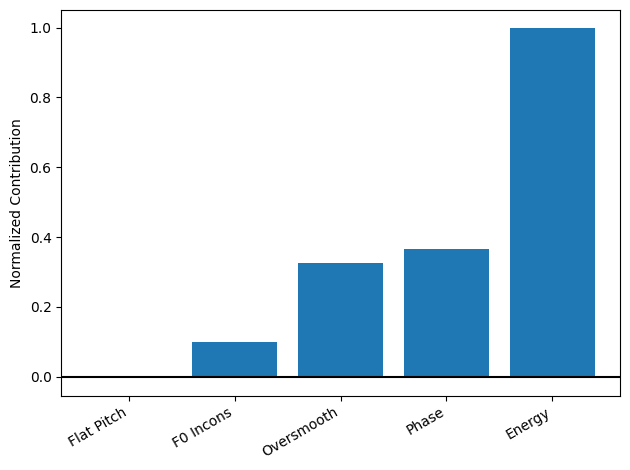

In [5]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/NEW/ALL"
res = analyze_ensemble(rootpath, expert_names=names)

### Analyze sigmoids

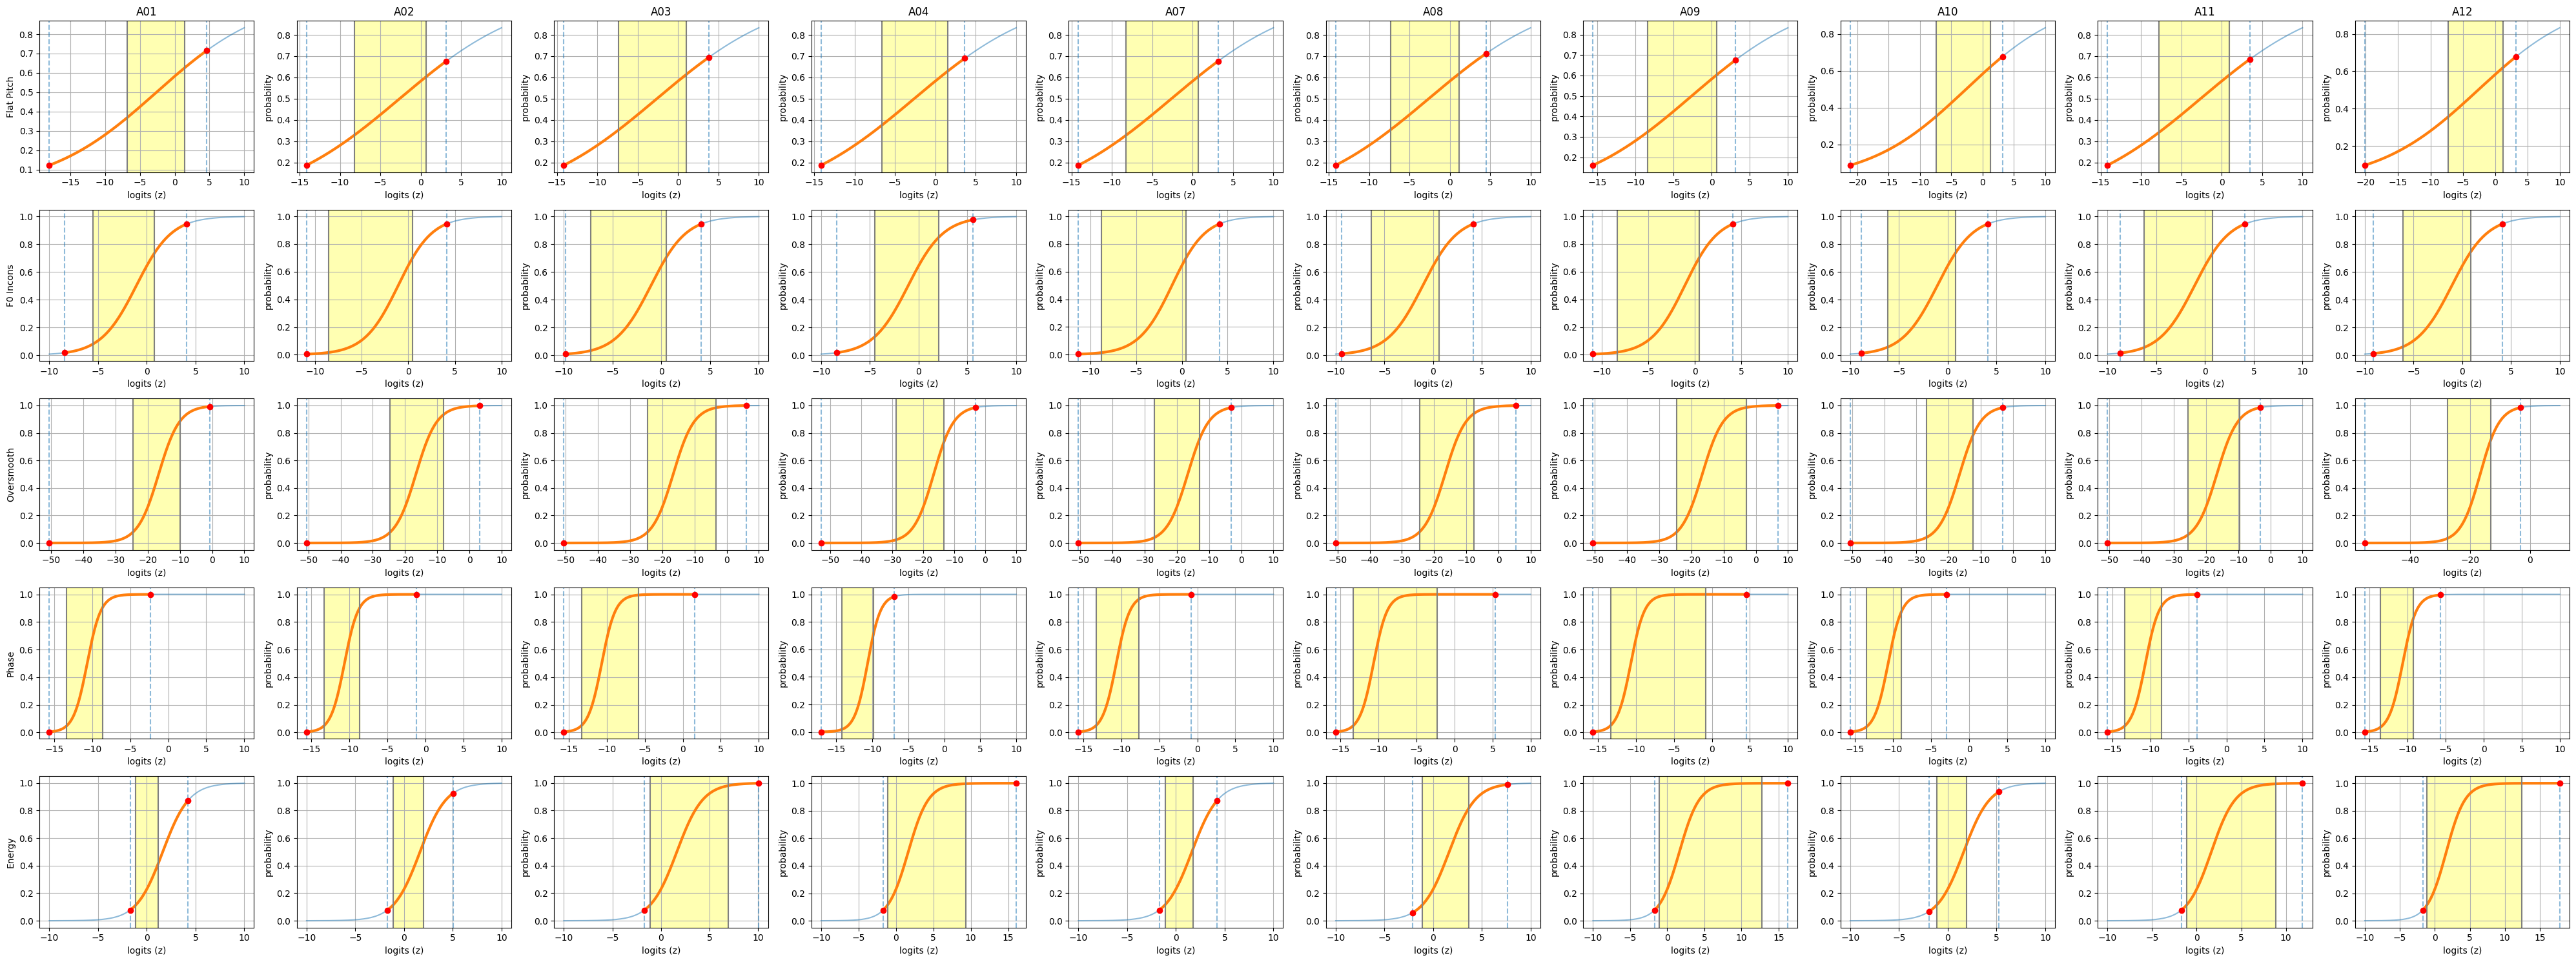

In [7]:
root_base = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/NEW"
names = ['Flat Pitch', 'F0 Incons', 'Oversmooth', 'Phase', 'Energy']
plot_platt_all_attacks(root_base, generator_list, names)


### Per attack


########################################################################################################################
#--------------------------------------------------------- A01 ---------------------------------------------------------#
########################################################################################################################

Loaded 1898 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 82.58%, EER: 24.44%
Real mean score: -1.2891
Fake mean score: -0.0425


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 57.62%, EER: 44.21%
Real mean score: 0.0091
Fake mean score: 0.0175

--- F0 Incons ---
AUC: 55.39%, EER: 46.33%
Real mean score: -0.1030
Fake mean score: -0.0419

--- Oversmooth ---
AUC: 81.23%, EER: 26.67%
Real mean score: -0.3415
Fake mean score: 0.4237

--- Phase ---
AUC: 73.15%, EER: 33.44%
Real mean score: -0.2409
Fake mean score: 0.2364

--- Energy ---
AUC: 52.77%, EER: 46.92%
Real mean score: -0.6129
Fake mean score: -0.6

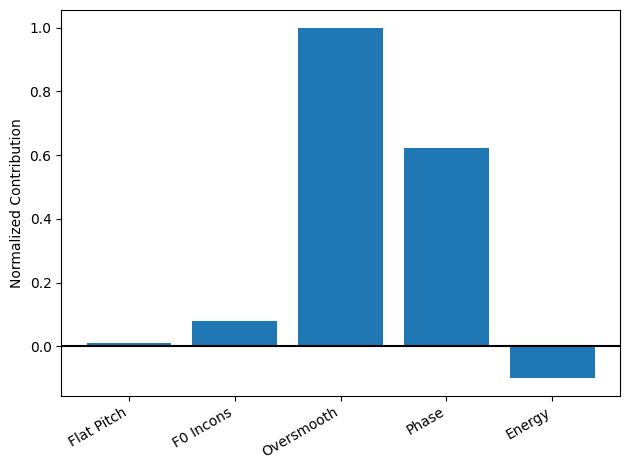


########################################################################################################################
#--------------------------------------------------------- A02 ---------------------------------------------------------#
########################################################################################################################

Loaded 1926 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 93.99%, EER: 12.49%
Real mean score: -1.2891
Fake mean score: 0.9949


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 30.83%, EER: 63.45%
Real mean score: 0.0091
Fake mean score: -0.0143

--- F0 Incons ---
AUC: 78.20%, EER: 29.44%
Real mean score: -0.1030
Fake mean score: 0.3319

--- Oversmooth ---
AUC: 90.83%, EER: 16.37%
Real mean score: -0.3415
Fake mean score: 1.0219

--- Phase ---
AUC: 72.40%, EER: 34.75%
Real mean score: -0.2409
Fake mean score: 0.2080

--- Energy ---
AUC: 59.46%, EER: 43.15%
Real mean score: -0.6129
Fake mean score: -0.55

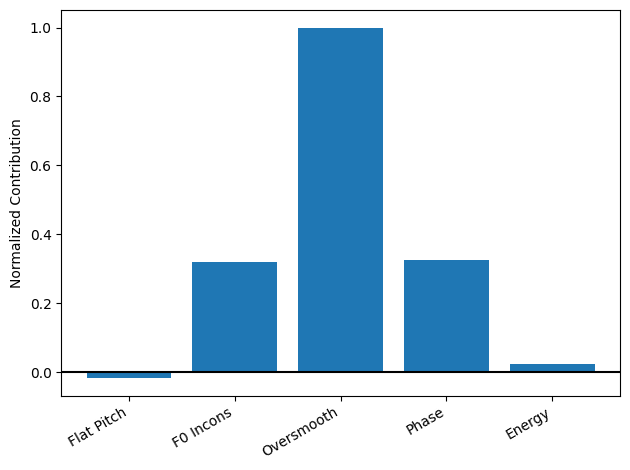


########################################################################################################################
#--------------------------------------------------------- A03 ---------------------------------------------------------#
########################################################################################################################

Loaded 1931 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 99.75%, EER: 2.55%
Real mean score: -1.2891
Fake mean score: 5.6739


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 39.10%, EER: 58.45%
Real mean score: 0.0091
Fake mean score: -0.0012

--- F0 Incons ---
AUC: 71.09%, EER: 34.55%
Real mean score: -0.1030
Fake mean score: 0.2076

--- Oversmooth ---
AUC: 96.43%, EER: 10.10%
Real mean score: -0.3415
Fake mean score: 1.5179

--- Phase ---
AUC: 88.08%, EER: 20.00%
Real mean score: -0.2409
Fake mean score: 0.9956

--- Energy ---
AUC: 96.84%, EER: 7.17%
Real mean score: -0.6129
Fake mean score: 2.9541


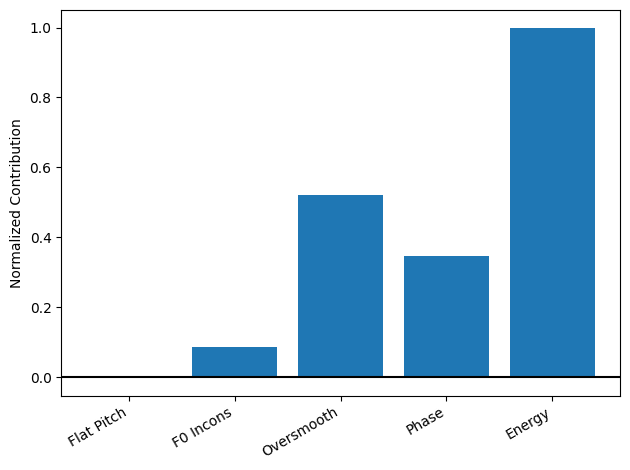


########################################################################################################################
#--------------------------------------------------------- A04 ---------------------------------------------------------#
########################################################################################################################

Loaded 1880 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 82.84%, EER: 26.04%
Real mean score: -1.2891
Fake mean score: 2.2296


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 56.84%, EER: 45.48%
Real mean score: 0.0091
Fake mean score: 0.0175

--- F0 Incons ---
AUC: 57.19%, EER: 43.02%
Real mean score: -0.1030
Fake mean score: -0.0421

--- Oversmooth ---
AUC: 39.87%, EER: 56.54%
Real mean score: -0.3415
Fake mean score: -0.5067

--- Phase ---
AUC: 41.82%, EER: 56.11%
Real mean score: -0.2409
Fake mean score: -0.3244

--- Energy ---
AUC: 89.30%, EER: 22.21%
Real mean score: -0.6129
Fake mean score: 3.0

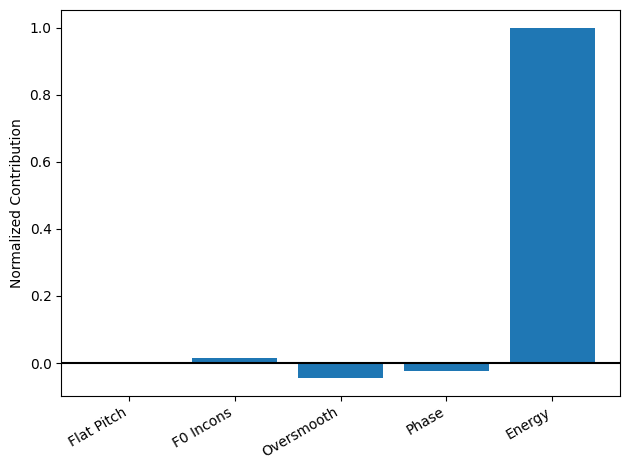


########################################################################################################################
#--------------------------------------------------------- A07 ---------------------------------------------------------#
########################################################################################################################

Loaded 1940 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 82.81%, EER: 23.49%
Real mean score: -1.2891
Fake mean score: -0.0144


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 28.99%, EER: 64.61%
Real mean score: 0.0091
Fake mean score: -0.0159

--- F0 Incons ---
AUC: 81.41%, EER: 26.57%
Real mean score: -0.1030
Fake mean score: 0.3811

--- Oversmooth ---
AUC: 45.08%, EER: 53.99%
Real mean score: -0.3415
Fake mean score: -0.4259

--- Phase ---
AUC: 83.97%, EER: 24.02%
Real mean score: -0.2409
Fake mean score: 0.6486

--- Energy ---
AUC: 66.75%, EER: 37.04%
Real mean score: -0.6129
Fake mean score: -0.

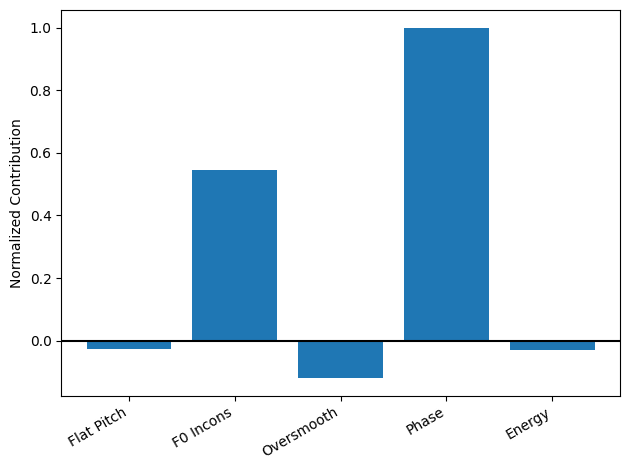


########################################################################################################################
#--------------------------------------------------------- A08 ---------------------------------------------------------#
########################################################################################################################

Loaded 1933 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 98.44%, EER: 5.75%
Real mean score: -1.2891
Fake mean score: 2.9711


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 47.09%, EER: 51.51%
Real mean score: 0.0091
Fake mean score: 0.0062

--- F0 Incons ---
AUC: 64.01%, EER: 39.62%
Real mean score: -0.1030
Fake mean score: 0.0765

--- Oversmooth ---
AUC: 84.26%, EER: 23.59%
Real mean score: -0.3415
Fake mean score: 0.8401

--- Phase ---
AUC: 97.17%, EER: 8.82%
Real mean score: -0.2409
Fake mean score: 1.6956

--- Energy ---
AUC: 81.63%, EER: 27.42%
Real mean score: -0.6129
Fake mean score: 0.3526



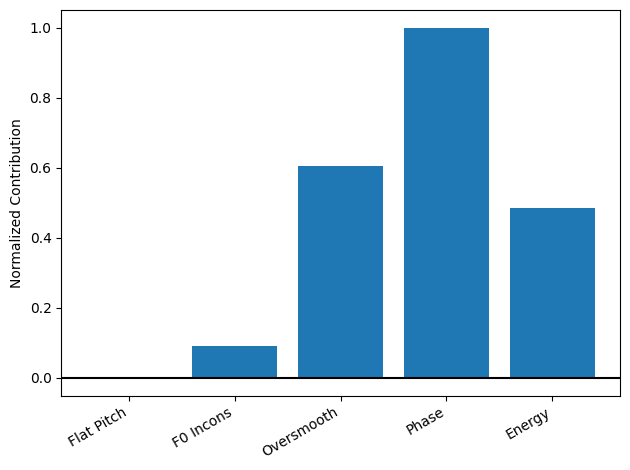


########################################################################################################################
#--------------------------------------------------------- A09 ---------------------------------------------------------#
########################################################################################################################

Loaded 1939 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 100.00%, EER: 0.00%
Real mean score: -1.2891
Fake mean score: 8.0917


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 26.06%, EER: 67.94%
Real mean score: 0.0091
Fake mean score: -0.0204

--- F0 Incons ---
AUC: 80.90%, EER: 28.16%
Real mean score: -0.1030
Fake mean score: 0.3588

--- Oversmooth ---
AUC: 95.77%, EER: 11.12%
Real mean score: -0.3415
Fake mean score: 1.5918

--- Phase ---
AUC: 98.97%, EER: 4.71%
Real mean score: -0.2409
Fake mean score: 1.9231

--- Energy ---
AUC: 99.38%, EER: 3.01%
Real mean score: -0.6129
Fake mean score: 4.2384


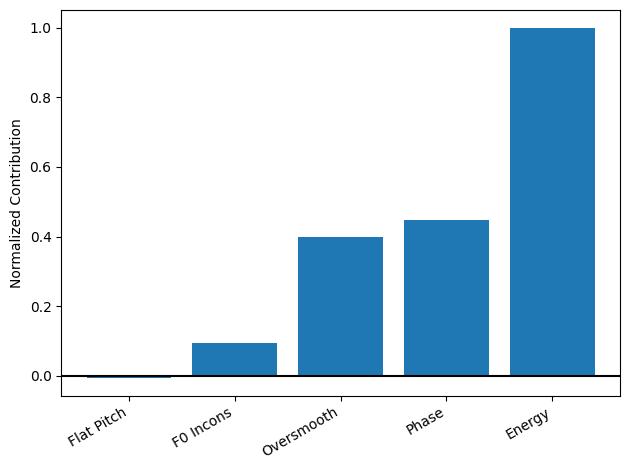


########################################################################################################################
#--------------------------------------------------------- A10 ---------------------------------------------------------#
########################################################################################################################

Loaded 1898 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 65.64%, EER: 38.47%
Real mean score: -1.2892
Fake mean score: -0.7791


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 43.06%, EER: 55.47%
Real mean score: 0.0091
Fake mean score: 0.0018

--- F0 Incons ---
AUC: 57.26%, EER: 45.38%
Real mean score: -0.1030
Fake mean score: -0.0094

--- Oversmooth ---
AUC: 52.23%, EER: 47.23%
Real mean score: -0.3416
Fake mean score: -0.3075

--- Phase ---
AUC: 68.30%, EER: 36.05%
Real mean score: -0.2409
Fake mean score: 0.1035

--- Energy ---
AUC: 63.99%, EER: 39.29%
Real mean score: -0.6129
Fake mean score: -0.

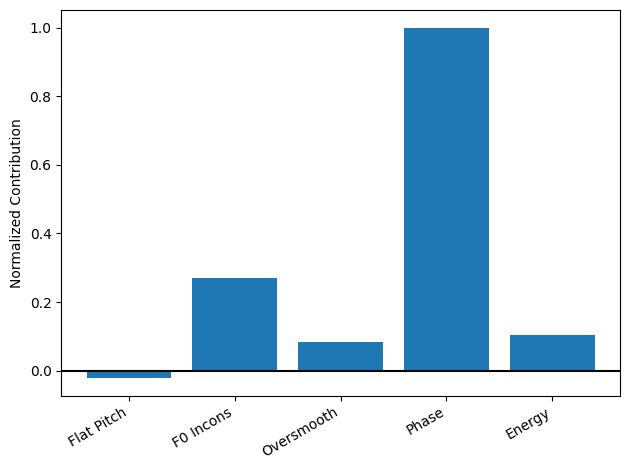


########################################################################################################################
#--------------------------------------------------------- A11 ---------------------------------------------------------#
########################################################################################################################

Loaded 1902 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 99.53%, EER: 3.12%
Real mean score: -1.2891
Fake mean score: 5.2180


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 41.55%, EER: 56.11%
Real mean score: 0.0091
Fake mean score: -0.0001

--- F0 Incons ---
AUC: 58.54%, EER: 44.42%
Real mean score: -0.1030
Fake mean score: 0.0147

--- Oversmooth ---
AUC: 79.07%, EER: 26.33%
Real mean score: -0.3415
Fake mean score: 0.4465

--- Phase ---
AUC: 78.28%, EER: 29.33%
Real mean score: -0.2409
Fake mean score: 0.3321

--- Energy ---
AUC: 99.09%, EER: 3.64%
Real mean score: -0.6129
Fake mean score: 4.4249


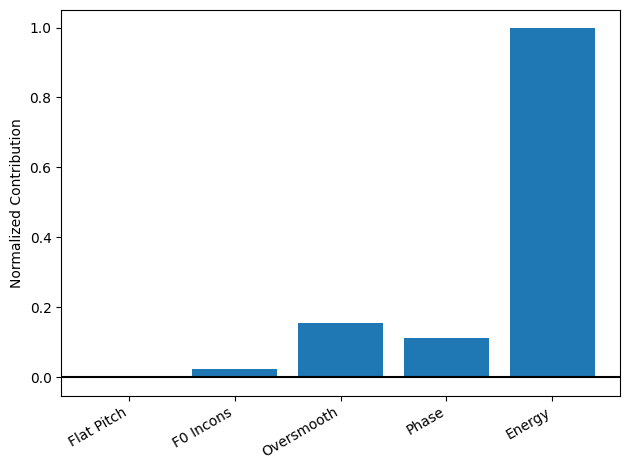


########################################################################################################################
#--------------------------------------------------------- A12 ---------------------------------------------------------#
########################################################################################################################

Loaded 1876 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 98.07%, EER: 4.49%
Real mean score: -1.2891
Fake mean score: 3.8449


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 45.30%, EER: 54.55%
Real mean score: 0.0091
Fake mean score: 0.0050

--- F0 Incons ---
AUC: 55.04%, EER: 47.17%
Real mean score: -0.1030
Fake mean score: -0.0297

--- Oversmooth ---
AUC: 40.92%, EER: 57.01%
Real mean score: -0.3415
Fake mean score: -0.4837

--- Phase ---
AUC: 59.28%, EER: 43.78%
Real mean score: -0.2409
Fake mean score: -0.0833

--- Energy ---
AUC: 99.17%, EER: 3.74%
Real mean score: -0.6129
Fake mean score: 4.436

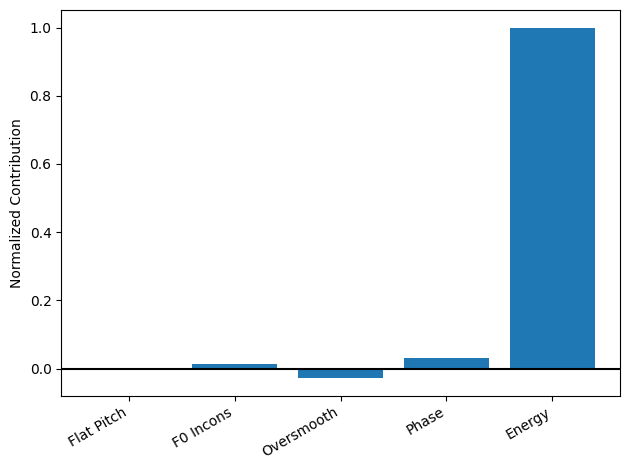

In [6]:
for a in generator_list:
    print(f"\n{'#'*120}")
    print(f"#{'-'*57} {a} {'-'*57}#")
    print(f"{'#'*120}\n")
    
    path = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/NEW/{a}"
    res = analyze_ensemble(path, expert_names=names)

# Test set: ASVspoof 5


In [8]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A14']    

Loaded 25006 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 67.14%, EER: 36.41%
Real mean score: -0.4192
Fake mean score: 0.1304


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 56.97%, EER: 45.49%
Real mean score: -0.0107
Fake mean score: 0.0169

--- F0 Incons ---
AUC: 48.48%, EER: 50.92%
Real mean score: 0.0213
Fake mean score: 0.0164

--- Oversmooth ---
AUC: 63.86%, EER: 39.28%
Real mean score: -0.2906
Fake mean score: 0.0494

--- Phase ---
AUC: 57.32%, EER: 44.66%
Real mean score: -0.1303
Fake mean score: 0.0252

--- Energy ---
AUC: 57.02%, EER: 44.67%
Real mean score: -0.0089
Fake mean score: 0.0224


=== Ranked Experts ===

 2 | Oversmooth   | contribution:   0.1744 | normalized:  1.0000
 3 | Phase        | contribution:   0.0797 | normalized:  0.4568
 4 | Energy       | contribution:   0.0154 | normalized:  0.0883
 0 | Flat Pitch   | contribution:   0.0137 | normalized:  0.0786
 1 | F0 Incons    | contribution:  -0.0031 | normalized: -0.0179

Summary:
Pos

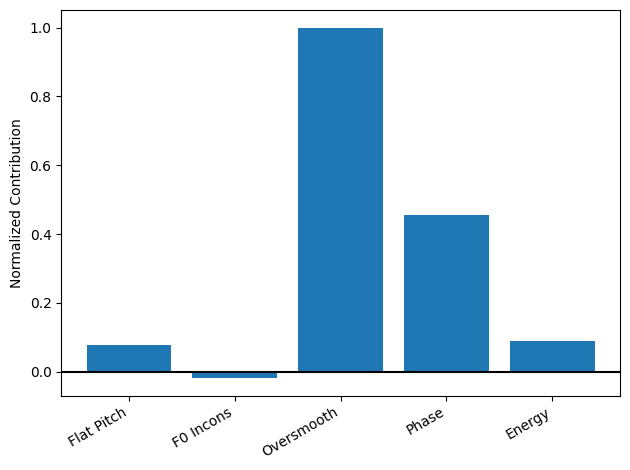

In [9]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_asv19/NEW/ALL"
res = analyze_ensemble(rootpath, expert_names=names)

## Analyze sigmoids

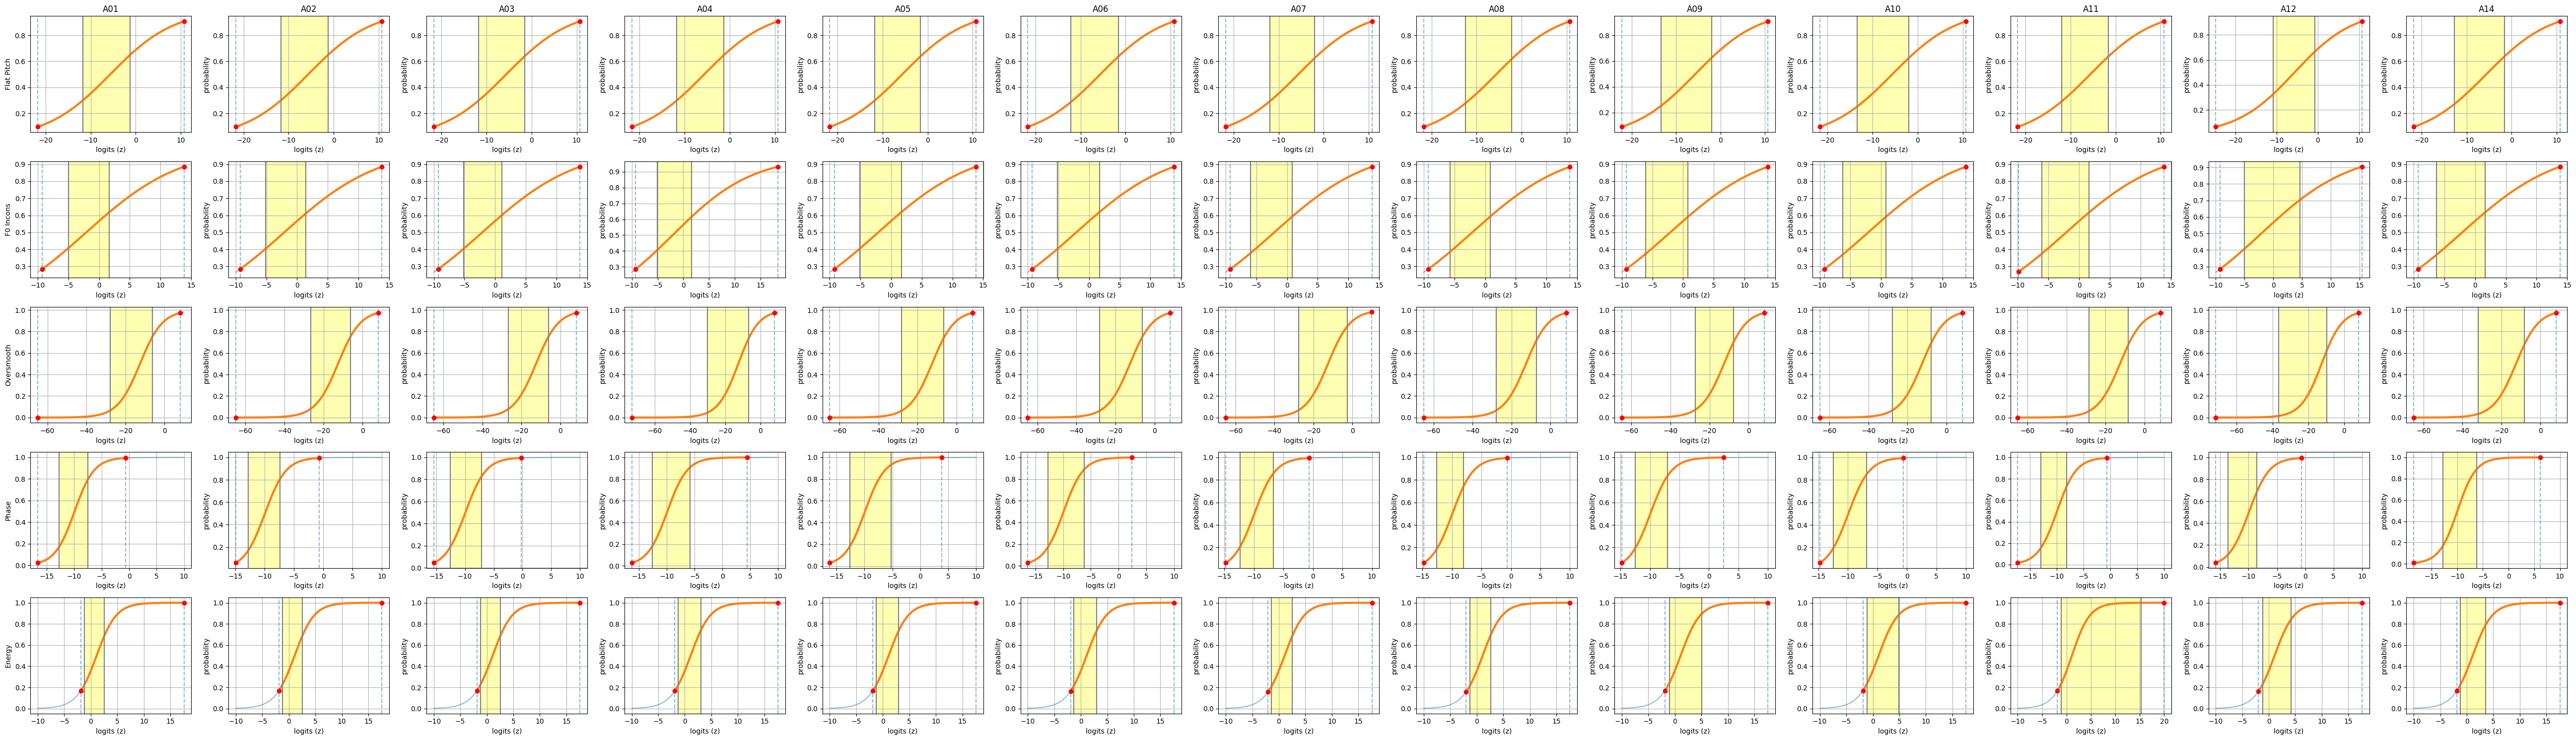

In [10]:
root_base = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_asv19/NEW"
names = ['Flat Pitch', 'F0 Incons', 'Oversmooth', 'Phase', 'Energy']
plot_platt_all_attacks(root_base, generator_list, names)


### Per attack


########################################################################################################################
#--------------------------------------------------------- A01 ---------------------------------------------------------#
########################################################################################################################

Loaded 1995 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 72.52%, EER: 31.93%
Real mean score: -0.4247
Fake mean score: 0.2389


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 59.56%, EER: 43.37%
Real mean score: -0.0102
Fake mean score: 0.0291

--- F0 Incons ---
AUC: 39.71%, EER: 56.12%
Real mean score: 0.0205
Fake mean score: 0.0020

--- Oversmooth ---
AUC: 72.56%, EER: 31.43%
Real mean score: -0.2874
Fake mean score: 0.2627

--- Phase ---
AUC: 54.18%, EER: 46.18%
Real mean score: -0.1365
Fake mean score: -0.0561

--- Energy ---
AUC: 57.12%, EER: 44.28%
Real mean score: -0.0111
Fake mean score: 0.001

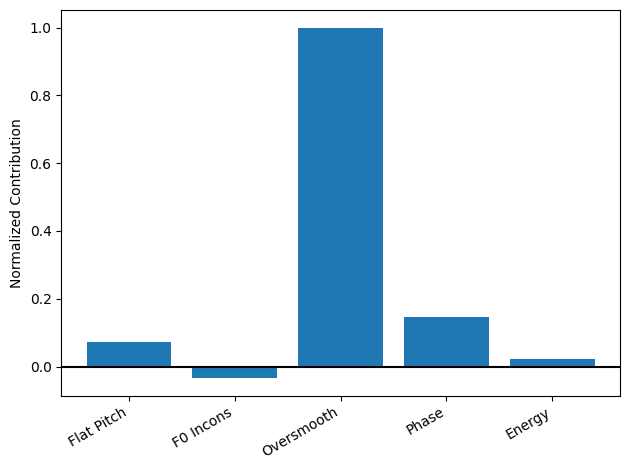


########################################################################################################################
#--------------------------------------------------------- A02 ---------------------------------------------------------#
########################################################################################################################

Loaded 1996 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 75.78%, EER: 30.20%
Real mean score: -0.4247
Fake mean score: 0.3538


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 61.41%, EER: 41.67%
Real mean score: -0.0102
Fake mean score: 0.0342

--- F0 Incons ---
AUC: 41.91%, EER: 55.00%
Real mean score: 0.0205
Fake mean score: 0.0134

--- Oversmooth ---
AUC: 76.01%, EER: 29.10%
Real mean score: -0.2874
Fake mean score: 0.3415

--- Phase ---
AUC: 54.79%, EER: 45.98%
Real mean score: -0.1365
Fake mean score: -0.0371

--- Energy ---
AUC: 57.54%, EER: 44.18%
Real mean score: -0.0111
Fake mean score: 0.001

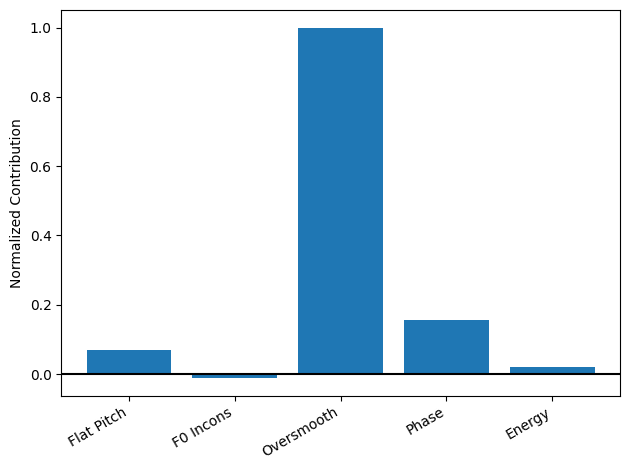


########################################################################################################################
#--------------------------------------------------------- A03 ---------------------------------------------------------#
########################################################################################################################

Loaded 1996 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 76.01%, EER: 29.82%
Real mean score: -0.4247
Fake mean score: 0.4235


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 58.36%, EER: 44.40%
Real mean score: -0.0102
Fake mean score: 0.0237

--- F0 Incons ---
AUC: 44.07%, EER: 53.20%
Real mean score: 0.0205
Fake mean score: 0.0238

--- Oversmooth ---
AUC: 74.27%, EER: 30.50%
Real mean score: -0.2874
Fake mean score: 0.3148

--- Phase ---
AUC: 61.92%, EER: 39.90%
Real mean score: -0.1365
Fake mean score: 0.0622

--- Energy ---
AUC: 56.88%, EER: 44.40%
Real mean score: -0.0111
Fake mean score: -0.001

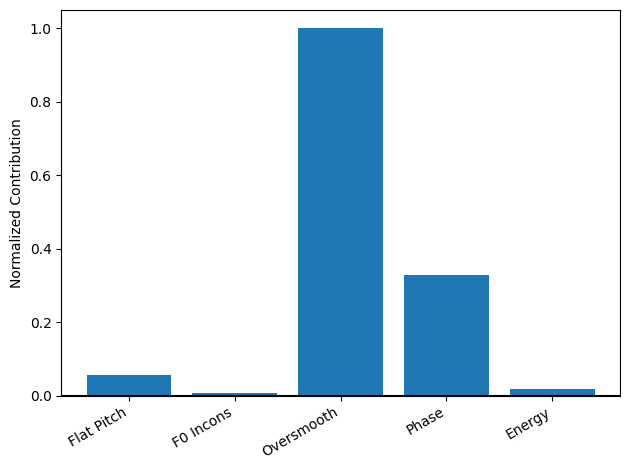


########################################################################################################################
#--------------------------------------------------------- A04 ---------------------------------------------------------#
########################################################################################################################

Loaded 1987 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 70.33%, EER: 34.01%
Real mean score: -0.4247
Fake mean score: 0.2146


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 60.17%, EER: 42.99%
Real mean score: -0.0102
Fake mean score: 0.0294

--- F0 Incons ---
AUC: 41.31%, EER: 55.02%
Real mean score: 0.0205
Fake mean score: 0.0045

--- Oversmooth ---
AUC: 60.77%, EER: 40.26%
Real mean score: -0.2874
Fake mean score: -0.0190

--- Phase ---
AUC: 66.29%, EER: 37.05%
Real mean score: -0.1365
Fake mean score: 0.2001

--- Energy ---
AUC: 55.77%, EER: 45.11%
Real mean score: -0.0111
Fake mean score: -0.00

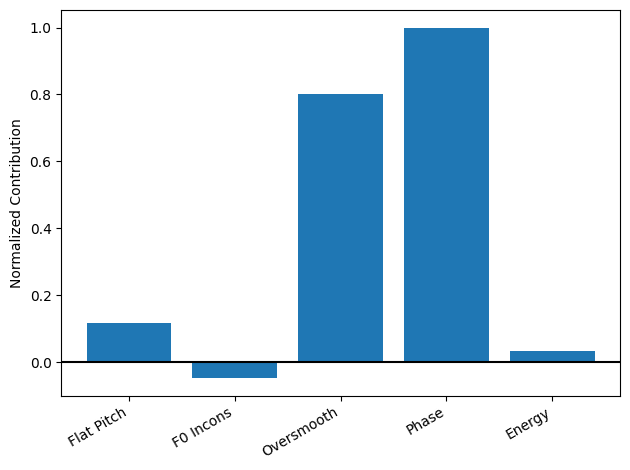


########################################################################################################################
#--------------------------------------------------------- A05 ---------------------------------------------------------#
########################################################################################################################

Loaded 1992 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 76.05%, EER: 29.72%
Real mean score: -0.4247
Fake mean score: 0.4370


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 58.42%, EER: 44.18%
Real mean score: -0.0102
Fake mean score: 0.0232

--- F0 Incons ---
AUC: 42.62%, EER: 54.02%
Real mean score: 0.0205
Fake mean score: 0.0083

--- Oversmooth ---
AUC: 66.96%, EER: 36.35%
Real mean score: -0.2874
Fake mean score: 0.1175

--- Phase ---
AUC: 70.74%, EER: 34.44%
Real mean score: -0.1365
Fake mean score: 0.2911

--- Energy ---
AUC: 54.84%, EER: 45.28%
Real mean score: -0.0111
Fake mean score: -0.003

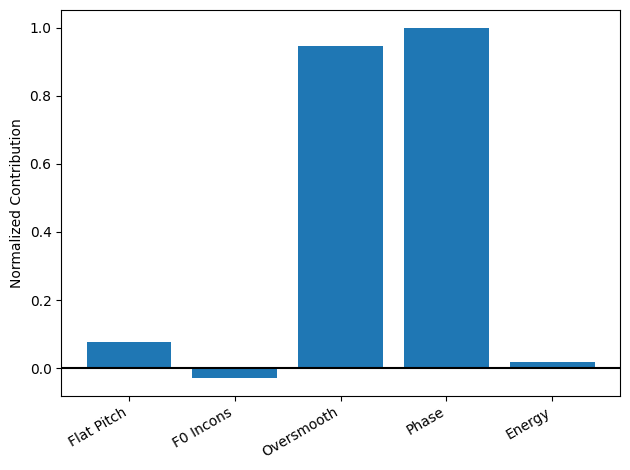


########################################################################################################################
#--------------------------------------------------------- A06 ---------------------------------------------------------#
########################################################################################################################

Loaded 1992 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 73.05%, EER: 32.33%
Real mean score: -0.4248
Fake mean score: 0.3143


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 57.37%, EER: 44.68%
Real mean score: -0.0102
Fake mean score: 0.0190

--- F0 Incons ---
AUC: 43.11%, EER: 54.02%
Real mean score: 0.0205
Fake mean score: 0.0085

--- Oversmooth ---
AUC: 67.57%, EER: 35.84%
Real mean score: -0.2874
Fake mean score: 0.1417

--- Phase ---
AUC: 63.83%, EER: 39.76%
Real mean score: -0.1365
Fake mean score: 0.1330

--- Energy ---
AUC: 59.75%, EER: 42.37%
Real mean score: -0.0111
Fake mean score: 0.0122

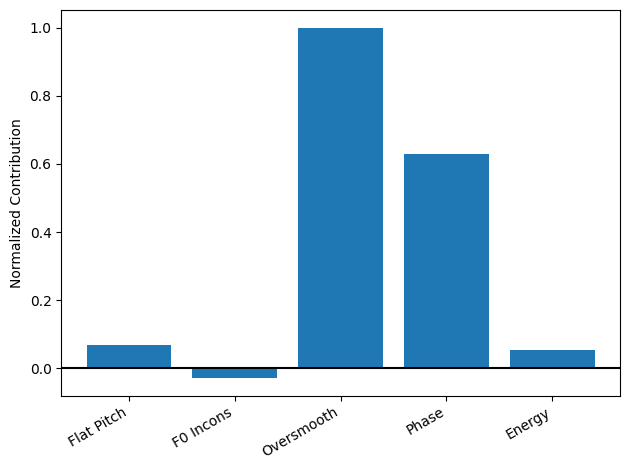


########################################################################################################################
#--------------------------------------------------------- A07 ---------------------------------------------------------#
########################################################################################################################

Loaded 1995 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 88.00%, EER: 18.98%
Real mean score: -0.4247
Fake mean score: 0.9875


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 51.28%, EER: 49.20%
Real mean score: -0.0102
Fake mean score: -0.0010

--- F0 Incons ---
AUC: 68.87%, EER: 36.04%
Real mean score: 0.0205
Fake mean score: 0.0941

--- Oversmooth ---
AUC: 81.94%, EER: 23.59%
Real mean score: -0.2874
Fake mean score: 0.6348

--- Phase ---
AUC: 73.69%, EER: 31.93%
Real mean score: -0.1365
Fake mean score: 0.2387

--- Energy ---
AUC: 63.25%, EER: 40.66%
Real mean score: -0.0111
Fake mean score: 0.021

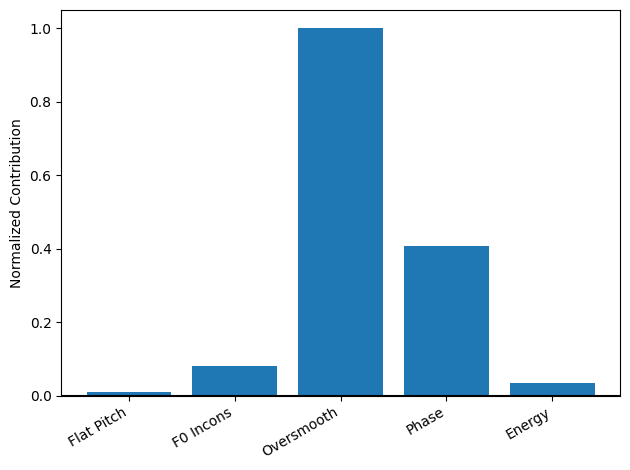


########################################################################################################################
#--------------------------------------------------------- A08 ---------------------------------------------------------#
########################################################################################################################

Loaded 1995 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 66.17%, EER: 37.65%
Real mean score: -0.4247
Fake mean score: -0.0228


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 45.61%, EER: 53.41%
Real mean score: -0.0102
Fake mean score: -0.0217

--- F0 Incons ---
AUC: 64.27%, EER: 40.16%
Real mean score: 0.0205
Fake mean score: 0.0825

--- Oversmooth ---
AUC: 66.95%, EER: 35.94%
Real mean score: -0.2873
Fake mean score: 0.0631

--- Phase ---
AUC: 52.16%, EER: 48.59%
Real mean score: -0.1365
Fake mean score: -0.1311

--- Energy ---
AUC: 53.81%, EER: 45.15%
Real mean score: -0.0111
Fake mean score: -0.

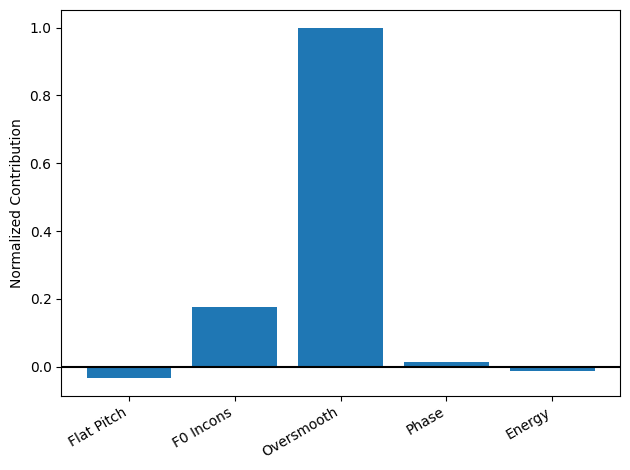


########################################################################################################################
#--------------------------------------------------------- A09 ---------------------------------------------------------#
########################################################################################################################

Loaded 1996 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 72.39%, EER: 33.43%
Real mean score: -0.4247
Fake mean score: 0.2066


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 50.68%, EER: 47.90%
Real mean score: -0.0102
Fake mean score: -0.0129

--- F0 Incons ---
AUC: 65.05%, EER: 39.86%
Real mean score: 0.0205
Fake mean score: 0.0836

--- Oversmooth ---
AUC: 61.12%, EER: 41.77%
Real mean score: -0.2874
Fake mean score: -0.0849

--- Phase ---
AUC: 66.01%, EER: 38.20%
Real mean score: -0.1365
Fake mean score: 0.1163

--- Energy ---
AUC: 58.44%, EER: 46.40%
Real mean score: -0.0111
Fake mean score: 0.10

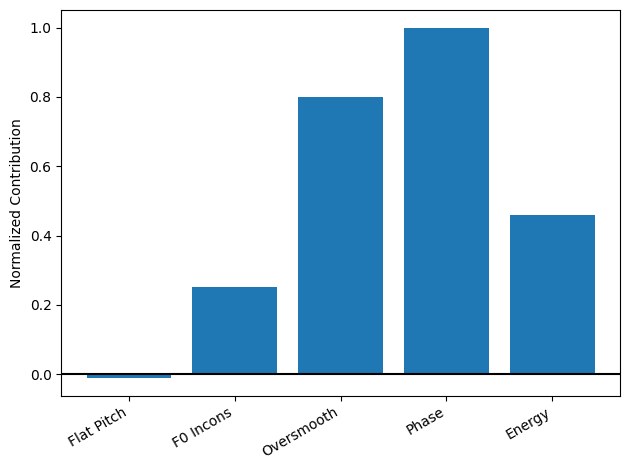


########################################################################################################################
#--------------------------------------------------------- A10 ---------------------------------------------------------#
########################################################################################################################

Loaded 1996 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 71.41%, EER: 34.40%
Real mean score: -0.4247
Fake mean score: 0.1792


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 52.50%, EER: 47.49%
Real mean score: -0.0102
Fake mean score: -0.0057

--- F0 Incons ---
AUC: 64.30%, EER: 40.56%
Real mean score: 0.0205
Fake mean score: 0.0820

--- Oversmooth ---
AUC: 59.44%, EER: 42.57%
Real mean score: -0.2873
Fake mean score: -0.1157

--- Phase ---
AUC: 66.37%, EER: 37.05%
Real mean score: -0.1365
Fake mean score: 0.1244

--- Energy ---
AUC: 56.74%, EER: 47.70%
Real mean score: -0.0111
Fake mean score: 0.09

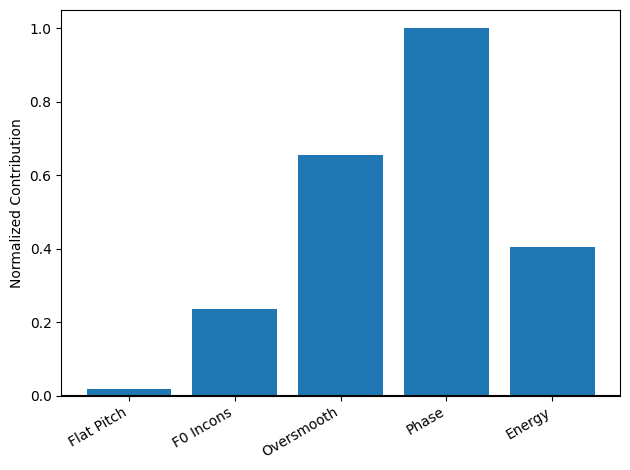


########################################################################################################################
#--------------------------------------------------------- A11 ---------------------------------------------------------#
########################################################################################################################

Loaded 1970 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 53.79%, EER: 47.74%
Real mean score: -0.4247
Fake mean score: -0.3471


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 51.38%, EER: 50.10%
Real mean score: -0.0102
Fake mean score: 0.0017

--- F0 Incons ---
AUC: 52.19%, EER: 49.50%
Real mean score: 0.0205
Fake mean score: 0.0353

--- Oversmooth ---
AUC: 55.34%, EER: 45.98%
Real mean score: -0.2874
Fake mean score: -0.2050

--- Phase ---
AUC: 39.75%, EER: 57.49%
Real mean score: -0.1365
Fake mean score: -0.2435

--- Energy ---
AUC: 69.30%, EER: 36.55%
Real mean score: -0.0111
Fake mean score: 0.0

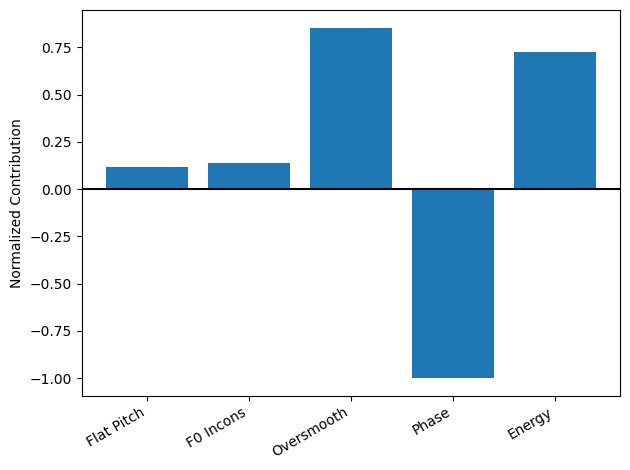


########################################################################################################################
#--------------------------------------------------------- A12 ---------------------------------------------------------#
########################################################################################################################

Loaded 1994 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 12.41%, EER: 79.72%
Real mean score: -0.4247
Fake mean score: -1.3999


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 72.75%, EER: 33.43%
Real mean score: -0.0102
Fake mean score: 0.0715

--- F0 Incons ---
AUC: 12.37%, EER: 79.86%
Real mean score: 0.0205
Fake mean score: -0.2164

--- Oversmooth ---
AUC: 20.57%, EER: 72.99%
Real mean score: -0.2874
Fake mean score: -0.8461

--- Phase ---
AUC: 24.35%, EER: 71.44%
Real mean score: -0.1365
Fake mean score: -0.3887

--- Energy ---
AUC: 46.18%, EER: 53.31%
Real mean score: -0.0111
Fake mean score: -0

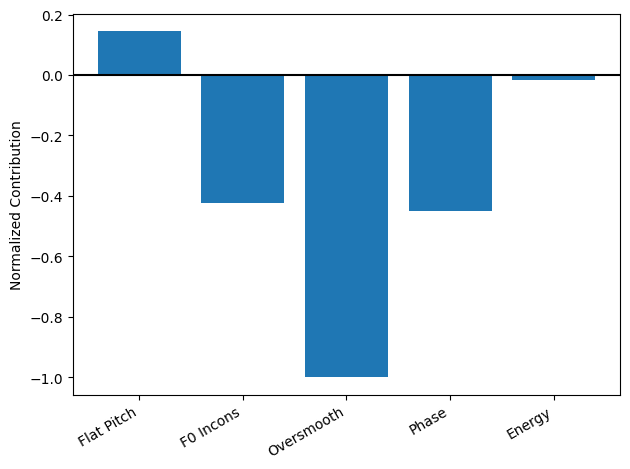


########################################################################################################################
#--------------------------------------------------------- A14 ---------------------------------------------------------#
########################################################################################################################

Loaded 1121 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 66.20%, EER: 37.60%
Real mean score: -0.4247
Fake mean score: 0.0613


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 57.98%, EER: 42.40%
Real mean score: -0.0102
Fake mean score: 0.0238

--- F0 Incons ---
AUC: 32.58%, EER: 71.69%
Real mean score: 0.0205
Fake mean score: -0.0222

--- Oversmooth ---
AUC: 51.07%, EER: 47.99%
Real mean score: -0.2874
Fake mean score: -0.3034

--- Phase ---
AUC: 64.07%, EER: 42.40%
Real mean score: -0.1365
Fake mean score: 0.3622

--- Energy ---
AUC: 59.60%, EER: 41.37%
Real mean score: -0.0111
Fake mean score: 0.00

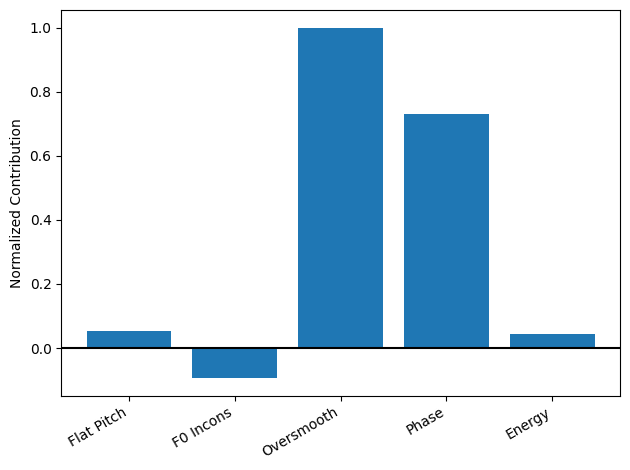

In [11]:
for a in generator_list:
    print(f"\n{'#'*120}")
    print(f"#{'-'*57} {a} {'-'*57}#")
    print(f"{'#'*120}\n")
    
    path = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_asv19/NEW/{a}"
    res = analyze_ensemble(path, expert_names=names)